In [7]:
from google.colab import files

uploaded = files.upload()

Saving logistics_shipment_dataset_5000.csv to logistics_shipment_dataset_5000.csv


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [9]:
df = pd.read_csv("logistics_shipment_dataset_5000.csv")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 5000
Columns: 12


In [10]:
df.head()

,Shipment_ID,Origin,Destination,Warehouse,Pickup_Time,Sorting_Time,Dispatch_Time,Delivery_Time,Transit_Time,Transport_Mode,Delivery_Status,Shipment_Volume
0,SHP00001,Pune,Hyderabad,WH_Delhi,2026-07-08 20:38:00,2026-07-09 02:46:44,2026-07-09 07:19:48,2026-07-10 14:15:07,23.99,Rail,Delayed,161
1,SHP00002,Hyderabad,Coimbatore,WH_Bengaluru,2026-02-18 09:27:00,2026-02-18 15:41:57,2026-02-18 19:00:54,2026-02-19 06:43:07,11.70,Truck,Delivered,227
2,SHP00003,Pune,Hyderabad,WH_Bengaluru,2026-05-15 20:08:00,2026-05-15 23:57:13,2026-05-16 04:27:40,2026-05-16 13:12:27,8.75,Truck,Delivered,206
3,SHP00004,Hyderabad,Delhi,WH_Mumbai,2026-03-22 03:49:00,2026-03-22 10:07:58,2026-03-22 14:29:45,2026-03-23 06:35:01,16.09,Truck,Delivered,399
4,SHP00005,Mumbai,Kochi,WH_Mumbai,2026-07-21 03:13:00,2026-07-21 09:16:30,2026-07-21 12:48:24,2026-07-22 13:06:30,11.62,Truck,Delayed,390


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Shipment_ID      5000 non-null   object 
 1   Origin           5000 non-null   object 
 2   Destination      5000 non-null   object 
 3   Warehouse        5000 non-null   object 
 4   Pickup_Time      5000 non-null   object 
 5   Sorting_Time     5000 non-null   object 
 6   Dispatch_Time    5000 non-null   object 
 7   Delivery_Time    5000 non-null   object 
 8   Transit_Time     5000 non-null   float64
 9   Transport_Mode   5000 non-null   object 
 10  Delivery_Status  5000 non-null   object 
 11  Shipment_Volume  5000 non-null   int64  
dtypes: float64(1), int64(1), object(10)
memory usage: 468.9+ KB


In [12]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Shipment_ID        0
Origin             0
Destination        0
Warehouse          0
Pickup_Time        0
Sorting_Time       0
Dispatch_Time      0
Delivery_Time      0
Transit_Time       0
Transport_Mode     0
Delivery_Status    0
Shipment_Volume    0
dtype: int64


In [13]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Shipment IDs:", df["Shipment_ID"].duplicated().sum())

Duplicate rows: 0
Duplicate Shipment IDs: 0


In [14]:
time_columns = [
    "Pickup_Time",
    "Sorting_Time",
    "Dispatch_Time",
    "Delivery_Time"
]

for col in time_columns:
    df[col] = pd.to_datetime(df[col])

print(df[time_columns].dtypes)

Pickup_Time      datetime64[ns]
Sorting_Time     datetime64[ns]
Dispatch_Time    datetime64[ns]
Delivery_Time    datetime64[ns]
dtype: object


In [15]:
df["Sorting_Duration_Hours"] = (
    df["Sorting_Time"] - df["Pickup_Time"]
).dt.total_seconds() / 3600

In [16]:
df["Dispatch_Duration_Hours"] = (
    df["Dispatch_Time"] - df["Sorting_Time"]
).dt.total_seconds() / 3600

In [17]:
df["Delivery_Duration_Hours"] = (
    df["Delivery_Time"] - df["Dispatch_Time"]
).dt.total_seconds() / 3600

In [18]:
df["Total_Duration_Hours"] = (
    df["Delivery_Time"] - df["Pickup_Time"]
).dt.total_seconds() / 3600

In [19]:
df[
    [
        "Shipment_ID",
        "Sorting_Duration_Hours",
        "Dispatch_Duration_Hours",
        "Delivery_Duration_Hours",
        "Total_Duration_Hours"
    ]
].head()

,Shipment_ID,Sorting_Duration_Hours,Dispatch_Duration_Hours,Delivery_Duration_Hours,Total_Duration_Hours
0,SHP00001,6.145556,4.551111,30.921944,41.618611
1,SHP00002,6.249167,3.315833,11.703611,21.268611
2,SHP00003,3.820278,4.507500,8.746389,17.074167
3,SHP00004,6.316111,4.363056,16.087778,26.766944
4,SHP00005,6.058333,3.531667,24.301667,33.891667


In [20]:
df.describe()

,Pickup_Time,Sorting_Time,Dispatch_Time,Delivery_Time,Transit_Time,Shipment_Volume,Sorting_Duration_Hours,Dispatch_Duration_Hours,Delivery_Duration_Hours,Total_Duration_Hours
count,5000,5000,5000,5000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,2026-05-13 02:20:58.512000,2026-05-13 08:07:46.467200,2026-05-13 11:57:54.256000,2026-05-14 06:27:41.412600064,15.959736,268.696400,5.779988,3.835497,18.496432,28.111917
min,2026-01-01 00:24:00,2026-01-01 05:11:17,2026-01-01 08:10:52,2026-01-01 19:02:13,2.000000,40.000000,1.058611,0.672222,2.000000,7.904167
25%,2026-03-06 02:50:45,2026-03-06 08:34:46,2026-03-06 12:24:31.750000128,2026-03-07 08:30:59.249999872,10.270000,149.000000,4.941250,3.193056,11.874514,21.000347
50%,2026-05-11 11:03:30,2026-05-11 17:01:17.500000,2026-05-11 20:37:21,2026-05-12 13:18:09,15.150000,270.500000,5.808889,3.849306,16.803889,26.467361
75%,2026-07-21 20:02:45,2026-07-22 00:07:51.750000128,2026-07-22 03:14:36,2026-07-22 18:18:11.750000128,20.142500,385.000000,6.641250,4.487014,24.194444,33.942986
max,2026-09-27 23:36:00,2026-09-28 05:53:59,2026-09-28 09:16:07,2026-09-29 11:28:06,51.070000,500.000000,10.060278,7.099444,63.751667,76.649722
std,NaN,NaN,NaN,NaN,8.536293,133.848249,1.242517,0.926046,10.034919,10.419036


In [21]:
df[
    [
        "Transit_Time",
        "Shipment_Volume",
        "Sorting_Duration_Hours",
        "Dispatch_Duration_Hours",
        "Delivery_Duration_Hours",
        "Total_Duration_Hours"
    ]
].describe()

,Transit_Time,Shipment_Volume,Sorting_Duration_Hours,Dispatch_Duration_Hours,Delivery_Duration_Hours,Total_Duration_Hours
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,15.959736,268.696400,5.779988,3.835497,18.496432,28.111917
std,8.536293,133.848249,1.242517,0.926046,10.034919,10.419036
min,2.000000,40.000000,1.058611,0.672222,2.000000,7.904167
25%,10.270000,149.000000,4.941250,3.193056,11.874514,21.000347
50%,15.150000,270.500000,5.808889,3.849306,16.803889,26.467361
75%,20.142500,385.000000,6.641250,4.487014,24.194444,33.942986
max,51.070000,500.000000,10.060278,7.099444,63.751667,76.649722


In [22]:
print(df["Delivery_Status"].value_counts())

Delivery_Status
Delivered    3929
Delayed      1071
Name: count, dtype: int64


In [23]:
print(
    df["Delivery_Status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Delivery_Status
Delivered    78.58
Delayed      21.42
Name: proportion, dtype: float64


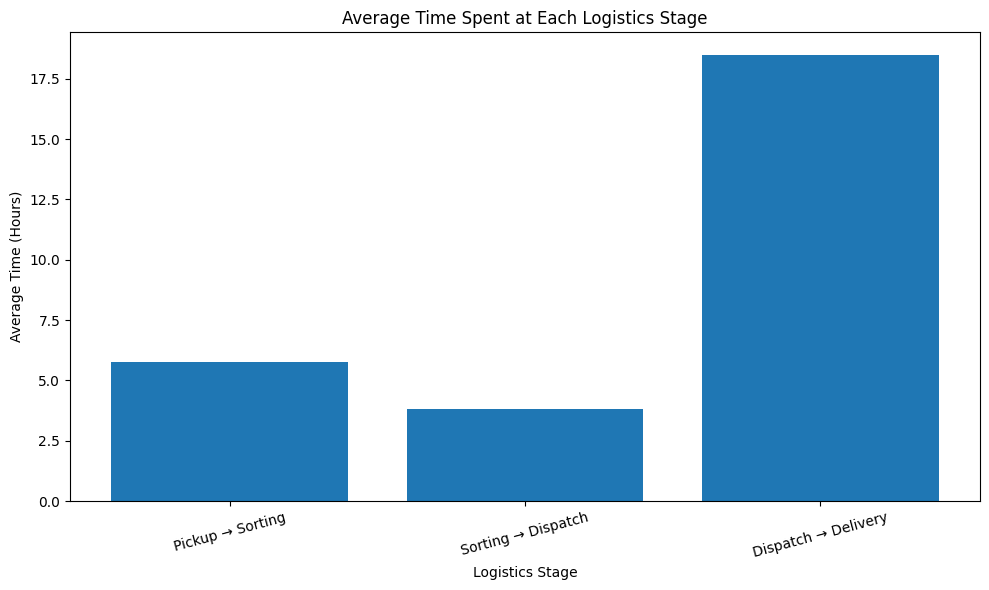

In [24]:
stage_times = {
    "Pickup → Sorting": df["Sorting_Duration_Hours"].mean(),
    "Sorting → Dispatch": df["Dispatch_Duration_Hours"].mean(),
    "Dispatch → Delivery": df["Delivery_Duration_Hours"].mean()
}

plt.figure(figsize=(10, 6))

plt.bar(
    stage_times.keys(),
    stage_times.values()
)

plt.title("Average Time Spent at Each Logistics Stage")
plt.xlabel("Logistics Stage")
plt.ylabel("Average Time (Hours)")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()